In [2]:
import torch

assert torch.cuda.is_available(), "No GPU. Use Runtime > Change runtime type > T4 GPU"

print(torch.cuda.get_device_name(0), "| PyTorch", torch.__version__)

Tesla T4 | PyTorch 2.11.0+cu130


In [3]:
from google.colab import drive
import os
drive.mount('/content/drive')
CK = '/content/drive/MyDrive/GeoFloodAI/checkpoints'
os.makedirs(CK, exist_ok=True)
print("Checkpoints folder:", CK)

Mounted at /content/drive
Checkpoints folder: /content/drive/MyDrive/GeoFloodAI/checkpoints


In [4]:
%cd /content
!test -d geoflood-ai || git clone https://github.com/Gayathri-337/geoflood-ai.git
%cd /content/geoflood-ai
!git pull
!pip -q install rasterio

/content
Cloning into 'geoflood-ai'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 48 (delta 10), reused 45 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 24.53 KiB | 12.27 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/geoflood-ai
Already up to date.


In [5]:
from google.colab import auth
auth.authenticate_user()   # sign in with your Google account when prompted

D = "ai/data/raw/sen1floods11"
!mkdir -p {D}/splits {D}/S1Hand {D}/LabelHand
!gsutil -m -q cp "gs://sen1floods11/v1.1/splits/flood_handlabeled/*.csv" {D}/splits/
!gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand {D}/S1Hand
!gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand {D}/LabelHand
!ls {D}/S1Hand | wc -l
!ls {D}/LabelHand | wc -l


both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".


both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

446
446


In [6]:
!python -m ai.src.preprocess_dataset

  GeoFlood AI - Phase 4 Preprocessing
train: 100% 252/252 [00:05<00:00, 42.95it/s]
val: 100% 89/89 [00:02<00:00, 32.68it/s]
test: 100% 90/90 [00:02<00:00, 43.29it/s]
bolivia: 100% 15/15 [00:00<00:00, 42.34it/s]

--- Summary ---
  split  chips  flood_pct_of_valid  ignored_pct  norm_min  norm_max
  train    252                9.51        13.29       0.0       1.0
    val     89               11.01        13.10       0.0       1.0
   test     90               12.30        13.35       0.0       1.0
bolivia     15               16.00        28.17       0.0       1.0

--- Class balance in the training split (valid pixels only) ---
  Flood pixels     : 5446678
  Not-flood pixels : 51832579
  Dry : flood ratio ~ 9.5 : 1  (we will use this in Phase 6)

Done. Files saved under: /content/geoflood-ai/ai/data/processed


In [7]:
!python -m ai.src.train --epochs 2 --out-dir /content/smoke_test

Device: cuda (Tesla T4)
Saving to: /content/smoke_test
Train chips: 252   Val chips: 89
Epoch   1/2 | train 0.6659 | val 0.5530 | IoU 0.4032 Dice 0.5746 P 0.9425 R 0.4133 | lr 1.0e-03 | 14s  <- best
Epoch   2/2 | train 0.5782 | val 0.4936 | IoU 0.5642 Dice 0.7214 P 0.8395 R 0.6324 | lr 1.0e-03 | 11s  <- best

Best epoch: 2  val IoU 0.5642  Dice 0.7214  precision 0.8395  recall 0.6324
Best model saved at: /content/smoke_test/unet_flood_best.pth


In [8]:
!python -m ai.src.train --epochs 60 --out-dir {CK} --resume

Device: cuda (Tesla T4)
Saving to: /content/drive/MyDrive/GeoFloodAI/checkpoints
Train chips: 252   Val chips: 89
Epoch   1/60 | train 0.6659 | val 0.5526 | IoU 0.4034 Dice 0.5749 P 0.9423 R 0.4136 | lr 1.0e-03 | 12s  <- best
Epoch   2/60 | train 0.5782 | val 0.4940 | IoU 0.5650 Dice 0.7221 P 0.8318 R 0.6379 | lr 1.0e-03 | 12s  <- best
Epoch   3/60 | train 0.5172 | val 0.4692 | IoU 0.5596 Dice 0.7176 P 0.7855 R 0.6605 | lr 1.0e-03 | 12s
Epoch   4/60 | train 0.4771 | val 0.4327 | IoU 0.5808 Dice 0.7348 P 0.8004 R 0.6791 | lr 1.0e-03 | 12s  <- best
Epoch   5/60 | train 0.4625 | val 0.3975 | IoU 0.5902 Dice 0.7423 P 0.7796 R 0.7084 | lr 1.0e-03 | 14s  <- best
Epoch   6/60 | train 0.4274 | val 0.3608 | IoU 0.5856 Dice 0.7386 P 0.7341 R 0.7433 | lr 1.0e-03 | 14s
Epoch   7/60 | train 0.3970 | val 0.4047 | IoU 0.4704 Dice 0.6398 P 0.9329 R 0.4869 | lr 1.0e-03 | 12s
Epoch   8/60 | train 0.3923 | val 0.5117 | IoU 0.3318 Dice 0.4983 P 0.3637 R 0.7908 | lr 1.0e-03 | 14s
Epoch   9/60 | train 0.392

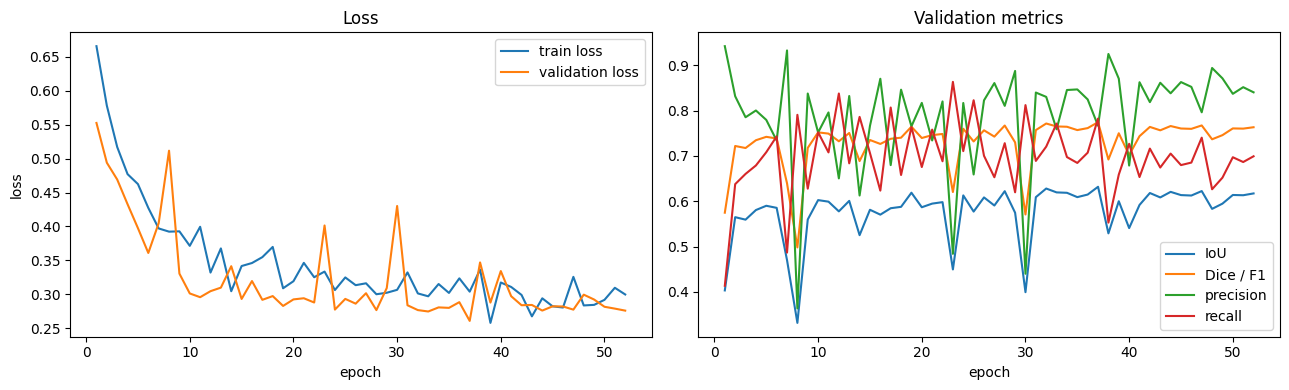

In [9]:
import json
import matplotlib.pyplot as plt

h = json.load(open(f"{CK}/history.json"))
ep = [r["epoch"] for r in h]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ep, [r["train_loss"] for r in h], label="train loss")
ax[0].plot(ep, [r["val_loss"] for r in h], label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss"); ax[0].legend()

ax[1].plot(ep, [r["val_iou"] for r in h], label="IoU")
ax[1].plot(ep, [r["val_dice"] for r in h], label="Dice / F1")
ax[1].plot(ep, [r["val_precision"] for r in h], label="precision")
ax[1].plot(ep, [r["val_recall"] for r in h], label="recall")
ax[1].set_xlabel("epoch"); ax[1].set_title("Validation metrics"); ax[1].legend()

fig.tight_layout()
fig.savefig(f"{CK}/training_curves.png", dpi=120)
plt.show()

In [10]:
from google.colab import files
files.download(f"{CK}/unet_flood_best.pth")
files.download(f"{CK}/history.json")
files.download(f"{CK}/training_curves.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from google.colab import files

files.download(f"{CK}/unet_flood_best.pth")
files.download(f"{CK}/history.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>